# Daily challenge — Airplane crashes and fatalities

Octopus Week 2 · Day 3

[Assignment](https://octopus.developers.institute/courses/collection/254/course/812/section/1706/chapter/4347)

Run cells in order. Source datasets are in `../data`; see the root README for setup and provenance.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'analysis_utils.py').exists())
sys.path.insert(0, str(ROOT))
sns.set_theme(style='whitegrid')
def load(kind, filename=None, **kwargs):
    files = list((ROOT / 'data' / kind).rglob(filename or '*.csv'))
    if len(files) != 1:
        raise ValueError(f'Select an unambiguous data file: {files}')
    return pd.read_csv(files[0], **kwargs)
def savefig(name):
    target = ROOT / 'figures'
    target.mkdir(exist_ok=True)
    plt.tight_layout()
    plt.savefig(target / (name + '.png'), dpi=140, bbox_inches='tight')
    plt.show()


## Scope and cleaning choices
Analyze recorded crashes, not the risk of taking a flight. The dataset lacks the number of flights, distance flown and exposure, and has historical reporting bias. Do not replace unknown fatalities or aboard counts with zero. Survival rates require positive aboard counts and fatalities no greater than aboard. Ground deaths are separate from onboard fatalities. Location is a free-text label, not a validated region.

In [2]:
raw=load('crashes',encoding='cp1252')
display(raw.head(3));print('Raw shape:',raw.shape)
display(raw.isna().sum().to_frame('missing'))
from analysis_utils import clean_crashes
df=clean_crashes(raw)
print('Duplicates removed:',len(raw)-len(df))
print('Invalid dates:',df['Date'].isna().sum())
print('Unknown/invalid survival rates:',df['SurvivalRate'].isna().sum())
df['OperatorType']=np.where(df['Operator'].fillna('').str.contains('military',case=False),'Military-labelled','Other/unknown')
display(df[['Date','Year','Aboard','Fatalities','SurvivalRate','OperatorType']].head())

,Date,Time,Location,Operator,Flight #,Route,AC Type,Registration,cn/ln,Aboard,Aboard Passangers,Aboard Crew,Fatalities,Fatalities Passangers,Fatalities Crew,Ground,Summary
0,9/17/1908,17:18,"Fort Myer, Virginia",Military - U.S. Army,NaN,Demonstration,Wright Flyer III,NaN,1,2.0,1.0,1.0,1.0,1.0,0.0,0.0,"During a demonstration flight, a U.S. Army fly..."
1,9/7/1909,NaN,"Juvisy-sur-Orge, France",NaN,NaN,Air show,Wright Byplane,SC1,NaN,1.0,0.0,1.0,1.0,0.0,0.0,0.0,Eugene Lefebvre was the first pilot to ever be...
2,7/12/1912,6:30,"Atlantic City, New Jersey",Military - U.S. Navy,NaN,Test flight,Dirigible,NaN,NaN,5.0,0.0,5.0,5.0,0.0,5.0,0.0,First U.S. dirigible Akron exploded just offsh...


Raw shape: (4998, 17)


,missing
Date,0
Time,1512
Location,4
Operator,10
Flight #,3669
Route,777
AC Type,15
Registration,274
cn/ln,668
Aboard,18


Duplicates removed: 0
Invalid dates: 0
Unknown/invalid survival rates: 23


,Date,Year,Aboard,Fatalities,SurvivalRate,OperatorType
0,1908-09-17,1908,2.0,1.0,0.5,Military-labelled
1,1909-09-07,1909,1.0,1.0,0.0,Other/unknown
2,1912-07-12,1912,5.0,5.0,0.0,Military-labelled
3,1913-08-06,1913,1.0,1.0,0.0,Other/unknown
4,1913-09-09,1913,20.0,14.0,0.3,Military-labelled


## Exploratory statistics and time trends

Recorded events: 4998 date range: 1908-09-17 00:00:00 2023-11-01 00:00:00
Known onboard fatalities sum: 111644.0
Known ground deaths sum: 8520.0
Occupant-weighted survival among valid crash records: 0.2819009243286387
Unweighted mean of per-crash survival rates: 0.181489019431307
Fatalities {'n': 4990, 'mean': 22.37354709418838, 'median': 11.0, 'sample std': 35.061740659743165, 'skew': 4.606031652398515}
SurvivalRate {'n': 4975, 'mean': 0.181489019431307, 'median': 0.0, 'sample std': 0.3117242492487905, 'skew': 1.5460751516056843}


,crashes,fatalities
Year,,
2014,23,1142.0
2015,18,759.0
2016,23,515.0
2017,15,210.0
2018,16,838.0
2019,13,305.0
2020,8,355.0
2021,9,185.0
2022,6,189.0


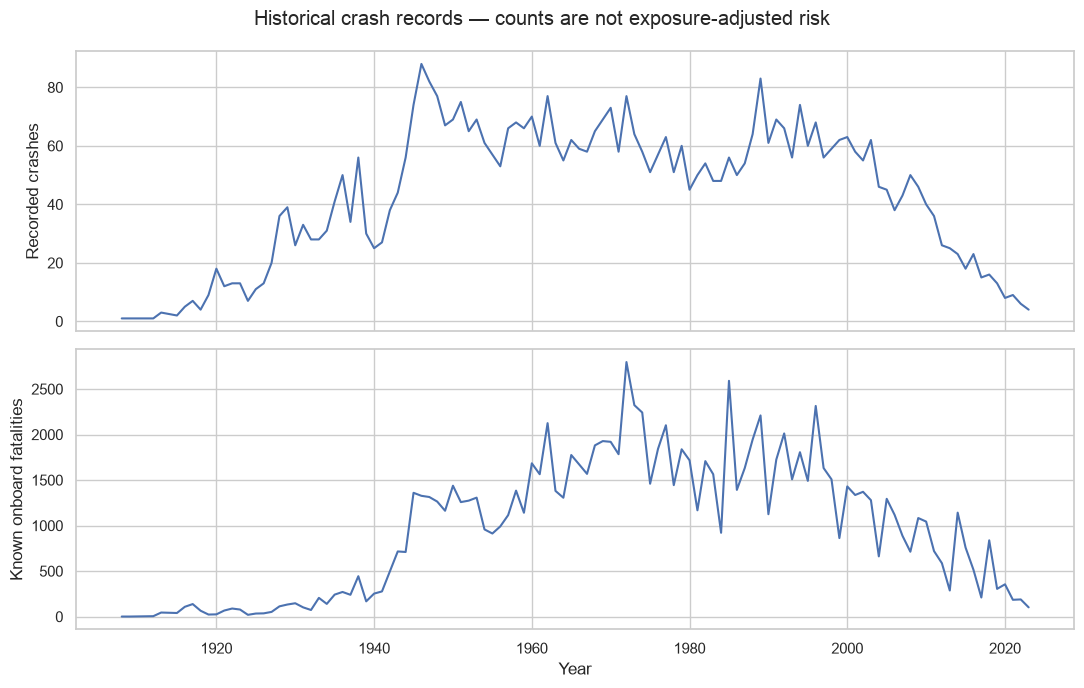

In [3]:
from scipy import stats
print('Recorded events:',len(df),'date range:',df['Date'].min(),df['Date'].max())
print('Known onboard fatalities sum:',df['Fatalities'].sum(min_count=1))
print('Known ground deaths sum:',df['Ground'].sum(min_count=1))
valid=df.dropna(subset=['SurvivalRate'])
pooled=(valid['Aboard'].sum()-valid['Fatalities'].sum())/valid['Aboard'].sum()
print('Occupant-weighted survival among valid crash records:',pooled)
print('Unweighted mean of per-crash survival rates:',valid['SurvivalRate'].mean())
for col in ['Fatalities','SurvivalRate']:
    s=df[col].dropna()
    desc=stats.describe(s,ddof=1)
    print(col,{'n':len(s),'mean':float(desc.mean),'median':float(np.median(s)),'sample std':float(np.sqrt(desc.variance)),'skew':float(desc.skewness)})
yearly=df.groupby('Year').agg(crashes=('Date','size'),fatalities=('Fatalities',lambda s:s.sum(min_count=1)))
display(yearly.tail(10))
yearly.to_csv(ROOT/'day3'/'crashes_by_year.csv')
fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True)
yearly['crashes'].plot(ax=axes[0]);axes[0].set_ylabel('Recorded crashes')
yearly['fatalities'].plot(ax=axes[1]);axes[1].set_ylabel('Known onboard fatalities');axes[1].set_xlabel('Year')
fig.suptitle('Historical crash records — counts are not exposure-adjusted risk')
savefig('day3_crash_time_series')

## Statistical comparison: 1990s versus 2000s
Use a two-sided Welch t test of mean onboard fatalities per recorded event (α=0.05). Decades are selected explicitly rather than searching for the smallest p value. Heavy tails and possible operator/event dependence limit the interpretation. Report a 95% confidence interval for the mean difference and a Mann–Whitney sensitivity test, which tests distributions rather than simply means.

n: 631 506 means: 25.33122028526149 22.08300395256917
Difference (1990s minus 2000s): 3.2482163326923192 95% CI: ConfidenceInterval(low=np.float64(-1.469925249716093), high=np.float64(7.9663579151007315))
Welch t: 1.3508228264500262 p: 0.17702894703473607
Insufficient evidence to reject equal means
Mann–Whitney sensitivity: MannwhitneyuResult(statistic=np.float64(175991.5), pvalue=np.float64(0.002935657635496384))


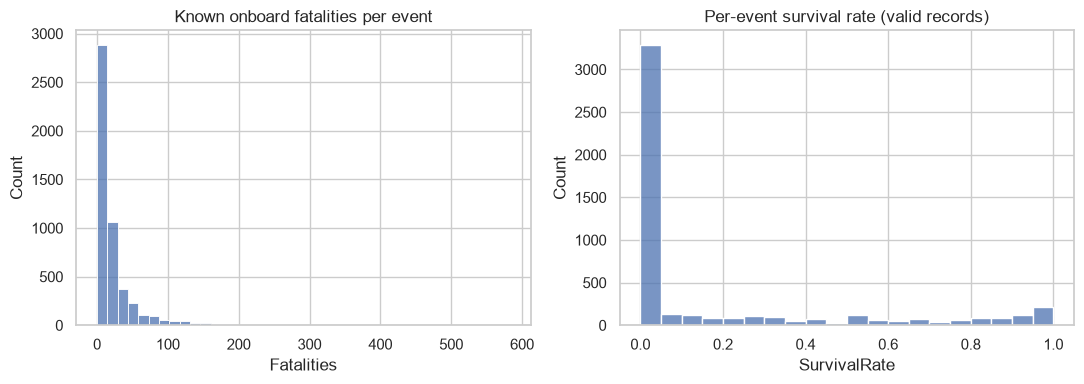

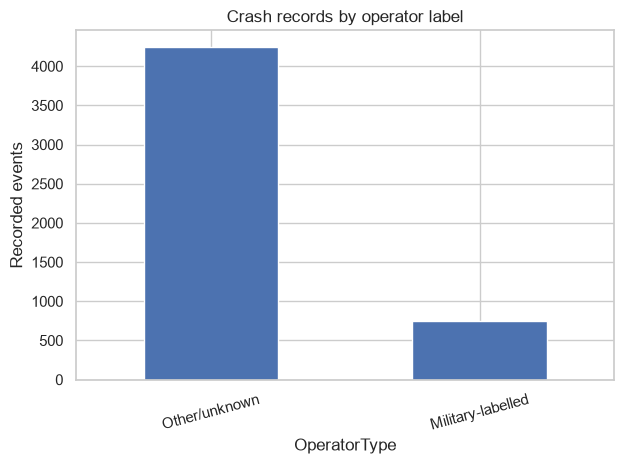

In [4]:
a=df.loc[df['Decade']==1990,'Fatalities'].dropna().to_numpy()
b=df.loc[df['Decade']==2000,'Fatalities'].dropna().to_numpy()
welch=stats.ttest_ind(a,b,equal_var=False)
ci=welch.confidence_interval(.95)
print('n:',len(a),len(b),'means:',a.mean(),b.mean())
print('Difference (1990s minus 2000s):',a.mean()-b.mean(),'95% CI:',ci)
print('Welch t:',welch.statistic,'p:',welch.pvalue)
print('Reject equal means' if welch.pvalue<.05 else 'Insufficient evidence to reject equal means')
print('Mann–Whitney sensitivity:',stats.mannwhitneyu(a,b,alternative='two-sided'))
fig,axes=plt.subplots(1,2,figsize=(11,4))
sns.histplot(df['Fatalities'].dropna(),bins=40,ax=axes[0]);axes[0].set_title('Known onboard fatalities per event')
sns.histplot(df['SurvivalRate'].dropna(),bins=20,ax=axes[1]);axes[1].set_title('Per-event survival rate (valid records)')
savefig('day3_crash_distributions')
counts=df['OperatorType'].value_counts()
counts.plot.bar();plt.ylabel('Recorded events');plt.title('Crash records by operator label');plt.xticks(rotation=15)
savefig('day3_operator_groups')

## Findings and limits
The 4,998 records span 1908–2023. Known onboard deaths total 111,644; eight fatality counts are unknown. Fatalities per recorded crash have a mean of 22.37 and median of 11, consistent with a right-skewed severity distribution. Survival is computable for 4,975 records: their occupant-weighted rate is 28.19%, while the mean event rate is 18.15%. These answer different questions.

The 1990s–2000s mean difference is 3.25 fatalities per recorded event, with Welch p=0.177 and 95% CI [-1.47, 7.97]; the data do not reject equal means at 5%. Mann–Whitney p=0.00294 indicates a distributional/rank difference under its assumptions. These tests concern different null hypotheses, so their different decisions are not a contradiction; the skewed data warrant caution.

Pandas supports parsing, missingness auditing and year/decade grouping. NumPy supports valid-denominator calculations and numeric summaries. SciPy provides distribution statistics, Welch inference and a nonparametric sensitivity comparison. Matplotlib/Seaborn show the temporal pattern and highly uneven event sizes.

The displayed summaries distinguish a typical event (median), an event-weighted mean survival rate and an occupant-weighted survival proportion. Large fatality events can dominate means; missing counts are excluded and their number is reported. The decade test concerns mean severity **conditional on a recorded crash**, not whether flying became safer. Neither declining event counts nor an observed difference establishes an exposure-adjusted safety improvement. A follow-up needs flight volume, consistent reporting coverage and a validated regional taxonomy.